# Canopy height case study

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
Bringing it all together: predicting vegetation height from SWISSIMAGE aerial photos at two Swiss forest sites
</div>
<!-- markdownlint-enable MD033 -->

---

Pages 4–7 used {term}`NDVI <Normalized Difference Vegetation Index>` as the target, a value the model could in principle compute from its input. This page applies the complete workflow to a target that no formula can deliver: the **height of the vegetation**, predicted from a single aerial photograph. You train on one forest site in the canton of Graubünden and test on a second site the model has never seen.

---

## 1. Motivation

{term}`Canopy height <Canopy Height>` is one of the most useful variables in forestry and ecology: it is related to timber volume, biomass and carbon, habitat structure and forest development stage. It is usually measured with airborne {term}`LiDAR` or by matching stereo aerial images, both of which are expensive and repeated only every few years. Orthophotos, on the other hand, are available for many areas and years, including historical ones. If a model can estimate height from an orthophoto, it can extend height maps to places and dates without 3D data.

The task is genuinely hard. A single orthophoto contains no direct height information; the model has to infer it from indirect clues: crown size and texture, shadows, the type of vegetation, and the surroundings. This page therefore also asks the question every regression project must answer: is the model better than simple alternatives?

---

## 2. Core idea

The data come from two 1.5 × 1.5 km forest sites in Graubünden, both at 1 m resolution and both from 2025:

| Data | Content | Source |
| --- | --- | --- |
| {term}`SWISSIMAGE` | RGB orthophoto, resampled from 10 cm to 1 m | Federal Office of Topography swisstopo |
| {term}`Vegetation height model <Vegetation Height Model>` (VHM) | Height of the vegetation above ground, in metres | Swiss National Forest Inventory (NFI), {abbr}`WSL (Swiss Federal Institute for Forest, Snow and Landscape Research)` and {abbr}`FOEN (Federal Office for the Environment)` |

The VHM is produced by matching swisstopo's stereo aerial images from the leaf-on flights to compute a surface model, then subtracting the terrain height (swissALTI3D); buildings are removed. The reference and the input therefore come from the same flights: the stereo images contain the 3D information, a single orthophoto does not.

The workflow repeats every step of this lesson, in condensed form:

| Step | Page | On this page |
| --- | --- | --- |
| Inspect data, check scaling, tile, split by location | 4 | B–E |
| Train with settings you can change | 5 | F |
| Predict wall-to-wall, with overlap and clipping | 6 | G |
| Evaluate held-out data, baselines, residuals by group and on the map | 7 | H–K |

```{admonition} Training takes a few minutes
:class: note
With the default settings, training takes about 2 minutes on an Apple M3 laptop (Apple {term}`GPU`), and roughly 30–60 minutes on a {abbr}`CPU (central processing unit)`. The outputs on this page come from one such run; your numbers will differ slightly.
```

---

## 3. Workflow

### A. Imports and settings

In [1]:
import json
import logging
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
for name in ["lightning.pytorch", "lightning.fabric", "rasterio"]:
    logging.getLogger(name).setLevel(logging.ERROR)

import geoai
import lightning as L
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from sklearn.ensemble import RandomForestRegressor

In [2]:
# ============================ EXPERIMENT SETTINGS ============================
TRAIN_SITE = "a"  # "a" or "b"; the other site is used as the test site
LOSS = "mse"  # "mse", "l1" or "huber" (page 3)
LEARNING_RATE = 1e-3
RESCALE_INPUT = True  # scale the 8-bit images to 0-1 before tiling (see step D)
ENCODER = "resnet34"
MAX_EPOCHS = 100
PATIENCE = 20
SEED = 0
# ==============================================================================

TEST_SITE = "b" if TRAIN_SITE == "a" else "a"
EXPERIMENT = f"vhm_train{TRAIN_SITE}_{ENCODER}_{LOSS}_lr{LEARNING_RATE:g}_rescale{int(RESCALE_INPUT)}_seed{SEED}"
RUN_DIR = Path("regression_runs") / EXPERIMENT
L.seed_everything(SEED, workers=True)
print("Experiment:", EXPERIMENT, "| test site:", TEST_SITE)

Experiment: vhm_traina_resnet34_mse_lr0.001_rescale1_seed0 | test site: b


### B. Download and inspect the data

In [3]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
BASE_URL = "https://data.source.coop/giuz/sds320/L11/data"

files = {}
for site in ["a", "b"]:
    for kind in ["swissimage", "vhm"]:
        name = f"site_{site}_{kind}_1m_2056.tif"
        files[(site, kind)] = geoai.download_file(f"{BASE_URL}/{name}", output_path=str(DATA_DIR / name))

for site in ["a", "b"]:
    for kind in ["swissimage", "vhm"]:
        with rasterio.open(files[(site, kind)]) as src:
            data = src.read(1)
            print(f"site {site} {kind:<10} {src.count} band(s) {src.dtypes[0]:<7} {src.width}x{src.height} "
                  f"{src.crs} {src.res[0]:.0f} m | values {data.min():.0f}-{data.max():.0f} | nodata {src.nodata}")
with rasterio.open(files[("a", "vhm")]) as src:
    print("\nVHM metadata:", src.tags())

site a swissimage 3 band(s) uint8   1500x1500 EPSG:2056 1 m | values 7-250 | nodata 0.0
site a vhm        1 band(s) float32 1500x1500 EPSG:2056 1 m | values 0-65 | nodata -9999.0
site b swissimage 3 band(s) uint8   1500x1500 EPSG:2056 1 m | values 4-250 | nodata 0.0
site b vhm        1 band(s) float32 1500x1500 EPSG:2056 1 m | values 0-65 | nodata -9999.0

VHM metadata: {'METHOD': '1:1 copy (grids coincide)', 'SOURCE': 'ch.bafu.landesforstinventar-vegetationshoehenmodell 2025 stereo', 'UNITS': 'metres', 'AREA_OR_POINT': 'Area'}


Both sites use the Swiss coordinate system LV95 (EPSG:2056) and share exactly the same 1 m grid for image and height model, so the pairs are aligned pixel by pixel. The orthophotos are 8-bit RGB (`uint8`, values 0–255); the heights are `float32` metres between 0 and 65. The metadata records how each file was produced, which is worth keeping when you prepare your own data.

### C. Look at the two sites

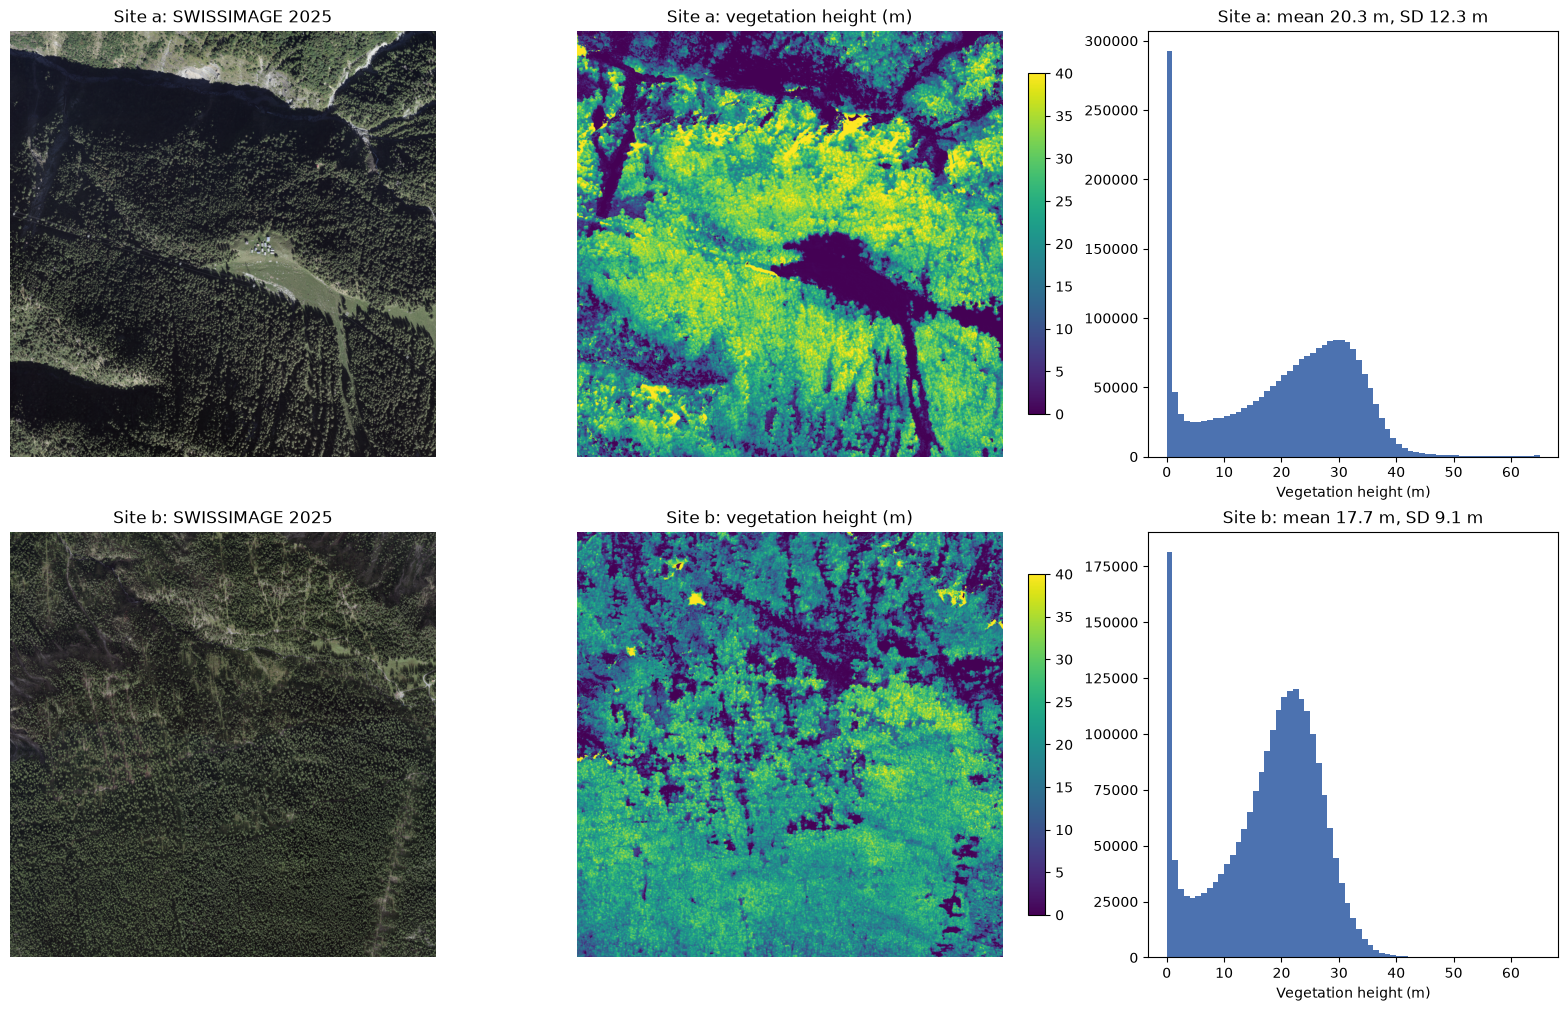

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10), constrained_layout=True,
                         gridspec_kw={"width_ratios": [1, 1, 0.8]})
heights = {}
for row, site in enumerate(["a", "b"]):
    with rasterio.open(files[(site, "swissimage")]) as src:
        axes[row, 0].imshow(src.read().transpose(1, 2, 0))
    with rasterio.open(files[(site, "vhm")]) as src:
        heights[site] = src.read(1)
    axes[row, 0].set_title(f"Site {site}: SWISSIMAGE 2025")
    im = axes[row, 1].imshow(heights[site], cmap="viridis", vmin=0, vmax=40)
    axes[row, 1].set_title(f"Site {site}: vegetation height (m)")
    fig.colorbar(im, ax=axes[row, 1], shrink=0.8)
    for ax in axes[row, :2]:
        ax.set_axis_off()
    axes[row, 2].hist(heights[site].ravel(), bins=65, range=(0, 65), color="#4c72b0")
    axes[row, 2].set_title(f"Site {site}: mean {heights[site].mean():.1f} m, SD {heights[site].std():.1f} m")
    axes[row, 2].set_xlabel("Vegetation height (m)")
plt.show()

Both sites are mostly forest on steep slopes, with meadows, clearings and paths. They differ in ways that matter for a model trained on one and applied to the other. Site A has taller trees (mean 20.3 m, with many stands around 30 m and some above 40 m) and large areas of deep shadow at the top and in the lower left of the image, where little can be seen at all. Site B is more evenly lit and more uniform, with lower trees (mean 17.7 m) and few above 30 m. Both histograms have a peak at 0 m: meadows, clearings, paths and rock.

### D. Scale the input: the 8-bit pitfall

Page 4 showed how `geoai` scales each tile: if its largest value is above 1.5, the tile is divided by 10,000, as for Sentinel-2 reflectance. What happens to an 8-bit aerial photo?

In [5]:
with rasterio.open(files[(TRAIN_SITE, "swissimage")]) as src:
    raw = src.read().astype("float32")
geoai_scaled = np.clip(raw, 0, 10000) / 10000
print(f"8-bit image as geoai would scale it: {geoai_scaled.min():.4f} to {geoai_scaled.max():.4f}")

imagenet_mean = np.array([0.485, 0.456, 0.406])[:, None, None]
imagenet_std = np.array([0.229, 0.224, 0.225])[:, None, None]
for name, x in [("divided by 10,000", geoai_scaled), ("divided by 255", raw / 255)]:
    z = (x - imagenet_mean) / imagenet_std
    print(f"{name:<18} -> after ImageNet normalization: mean {z.mean():5.2f}, SD {z.std():.3f}")

8-bit image as geoai would scale it: 0.0006 to 0.0253
divided by 10,000  -> after ImageNet normalization: mean -1.96, SD 0.134
divided by 255     -> after ImageNet normalization: mean -1.07, SD 0.691


Divided by 10,000, the 8-bit values end up between 0 and 0.025. For a three-band model with {term}`ImageNet` weights, `geoai` then also applies the ImageNet normalization, which expects values between 0 and 1. The result is an input in which every pixel is close to −2 and the differences between pixels are about five times smaller than with correct scaling (standard deviation 0.13 instead of 0.69). Nothing fails and no warning appears, but the pretrained encoder receives images that look nothing like the photographs it was trained on. Dividing by 255 first gives the network what it expects:

In [6]:
PREP_DIR = Path("data/prepared")
PREP_DIR.mkdir(parents=True, exist_ok=True)
image = {}
for site in ["a", "b"]:
    if not RESCALE_INPUT:
        image[site] = files[(site, "swissimage")]
        continue
    image[site] = str(PREP_DIR / f"site_{site}_swissimage_1m_0to1.tif")
    with rasterio.open(files[(site, "swissimage")]) as src:
        profile = src.profile
        scaled = src.read().astype("float32") / 255
    profile.update(dtype="float32", nodata=None)
    with rasterio.open(image[site], "w", **profile) as dst:
        dst.write(scaled)
print({site: Path(p).name for site, p in image.items()})

{'a': 'site_a_swissimage_1m_0to1.tif', 'b': 'site_b_swissimage_1m_0to1.tif'}


The rescaled images are written as `float32` GeoTIFFs with the same georeferencing. From here on, `image[site]` is the input for tiling and prediction. Set `RESCALE_INPUT = False` to see for yourself what the pitfall costs (step K shows what it did in our runs).

### E. Tiles and a spatial split

In [7]:
TILE_DIR = Path("regression_tiles") / f"vhm_site_{TRAIN_SITE}_rescale{int(RESCALE_INPUT)}"
image_paths, target_paths = geoai.create_regression_tiles(
    input_raster=image[TRAIN_SITE],
    target_raster=files[(TRAIN_SITE, "vhm")],
    output_dir=str(TILE_DIR),
    tile_size=256,
    stride=128,
    min_valid_ratio=0.9,
    target_min=0.0,
    target_max=65.0,
)

SPLIT_ROW = 1024
with rasterio.open(image[TRAIN_SITE]) as full:
    def tile_row(path):
        with rasterio.open(path) as tile:
            return full.index(tile.bounds.left + 0.5, tile.bounds.top - 0.5)[0]
    rows = [tile_row(p) for p in image_paths]

train = [(i, t) for i, t, r in zip(image_paths, target_paths, rows) if r + 256 <= SPLIT_ROW]
val = [(i, t) for i, t, r in zip(image_paths, target_paths, rows) if r >= SPLIT_ROW]
print(f"{len(image_paths)} tiles: {len(train)} for training (north), {len(val)} for validation (south)")

100 tiles: 70 for training (north), 20 for validation (south)


The same settings as on page 4: 256 × 256 pixel tiles (256 × 256 m) with half overlap, heights clipped to 0–65 m, and the southern part of the training site held out for validation. Each tile covers a few hundred tree crowns, enough context to see a stand, a clearing or a slope.

### F. Train the model

Training took 1.6 minutes, best checkpoint: resnet34_unet_epoch=33_val_loss=62.8900-v4.ckpt


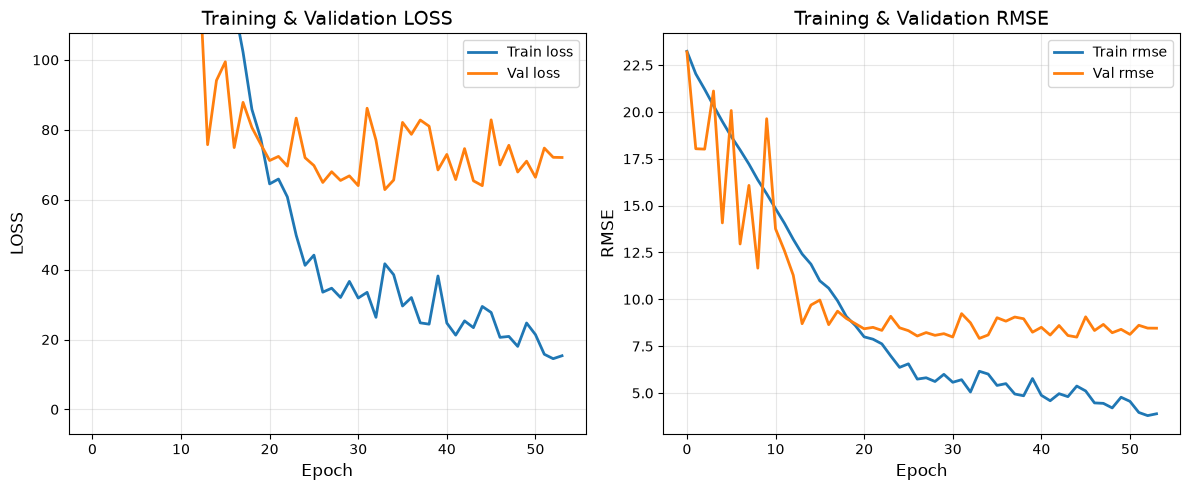

In [8]:
start = time.time()
model = geoai.train_pixel_regressor(
    train_image_paths=[i for i, _ in train],
    train_target_paths=[t for _, t in train],
    val_image_paths=[i for i, _ in val],
    val_target_paths=[t for _, t in val],
    in_channels=3,
    architecture="unet",
    encoder_name=ENCODER,
    encoder_weights="imagenet",
    output_dir=str(RUN_DIR),
    batch_size=8,
    num_epochs=MAX_EPOCHS,
    learning_rate=LEARNING_RATE,
    loss_type=LOSS,
    patience=PATIENCE,
    verbose=False,
)
print(f"Training took {(time.time() - start) / 60:.1f} minutes, best checkpoint: {Path(model.best_model_path).name}")
fig, history = geoai.plot_training_history(log_dir=str(RUN_DIR), metrics=["loss", "rmse"])

The right panel shows the {term}`root mean squared error <Root Mean Squared Error>` (RMSE) in metres, easier to interpret than the loss on the left, which is in square metres. The curves show textbook {term}`overfitting <Overfitting>`: after about 20 epochs the training RMSE keeps falling towards 4 m, while the validation RMSE stays at about 8 m. With only 70 training tiles from one site, the network starts to memorise them. {term}`Early stopping <Early Stopping>` keeps the checkpoint with the lowest validation loss, here from epoch 33.

### G. Predict both sites

In [9]:
pred_path = {}
for site in ["a", "b"]:
    pred_path[site] = str(RUN_DIR / "predictions" / f"vhm_site_{site}.tif")
    geoai.predict_raster(
        model=model,
        input_raster=image[site],
        output_raster=pred_path[site],
        tile_size=256,
        overlap=64,
        batch_size=8,
        clip_range=(0.0, 65.0),
        device=geoai.get_device(),
    )

def read(path):
    with rasterio.open(path) as src:
        arr = src.read(1).astype("float32")
        if src.nodata is not None:
            arr[arr == src.nodata] = np.nan
    return arr

pred = {site: read(pred_path[site]) for site in ["a", "b"]}
ref = {site: read(files[(site, "vhm")]) for site in ["a", "b"]}

`clip_range=(0, 65)` prevents negative heights, which the network's output layer would otherwise allow (page 3).

### H. Compare with simple baselines

A good regression evaluation always includes **{term}`baselines <Baseline Model>`**: simple methods that any model must beat to be worth its complexity. We use two:

- **Mean height:** predict the mean height of the training area everywhere. Its RMSE equals the spread of the heights; it is what you get with no information at all.
- **Random forest on pixel colours:** a {term}`random forest <Random Forest>` (L05) that predicts height from the red, green and blue values of each pixel alone, without any spatial context. Comparing it with the {term}`U-Net` shows how much the *context* (texture, shadows, crown shapes) contributes.

In [10]:
north = np.zeros(ref[TRAIN_SITE].shape, bool)
north[:SPLIT_ROW] = True  # rows of the training area
with rasterio.open(image[TRAIN_SITE]) as src:
    rgb_train = src.read().reshape(3, -1).T
with rasterio.open(image[TEST_SITE]) as src:
    rgb_test = src.read().reshape(3, -1).T

rng = np.random.default_rng(SEED)
train_pixels = rng.choice(np.flatnonzero(north), 100_000, replace=False)
forest = RandomForestRegressor(n_estimators=100, min_samples_leaf=20, n_jobs=-1, random_state=SEED)
forest.fit(rgb_train[train_pixels], ref[TRAIN_SITE].ravel()[train_pixels])
pred_rf = forest.predict(rgb_test).reshape(1500, 1500).astype("float32")
mean_height = float(ref[TRAIN_SITE][north].mean())

def regression_metrics(reference, prediction, mask=None):
    valid = np.isfinite(reference) & np.isfinite(prediction)
    if mask is not None:
        valid &= mask
    t, p = reference[valid], prediction[valid]
    e = p - t
    return {"RMSE (m)": np.sqrt(np.mean(e**2)), "MAE (m)": np.mean(np.abs(e)), "bias (m)": np.mean(e),
            "R²": 1 - np.sum(e**2) / np.sum((t - t.mean()) ** 2), "r": np.corrcoef(t, p)[0, 1]}

rows_table = [
    ("U-Net", f"site {TRAIN_SITE}, north (training area)", regression_metrics(ref[TRAIN_SITE], pred[TRAIN_SITE], north)),
    ("U-Net", f"site {TRAIN_SITE}, south (held out)", regression_metrics(ref[TRAIN_SITE], pred[TRAIN_SITE], ~north)),
    ("U-Net", f"site {TEST_SITE} (new site)", regression_metrics(ref[TEST_SITE], pred[TEST_SITE])),
    ("Random forest, pixel colours", f"site {TEST_SITE} (new site)", regression_metrics(ref[TEST_SITE], pred_rf)),
    ("Mean height of training area", f"site {TEST_SITE} (new site)",
     regression_metrics(ref[TEST_SITE], np.full_like(ref[TEST_SITE], mean_height))),
]
results = pd.DataFrame([{"method": m, "evaluated on": a, **d} for m, a, d in rows_table])
results.round(2)

,method,evaluated on,RMSE (m),MAE (m),bias (m),R²,r
0,U-Net,"site a, north (training area)",5.76,4.29,-2.22,0.81,0.93
1,U-Net,"site a, south (held out)",8.04,6.32,1.00,0.38,0.63
2,U-Net,site b (new site),7.35,5.64,0.43,0.34,0.59
3,"Random forest, pixel colours",site b (new site),9.60,7.59,1.87,-0.12,0.10
4,Mean height of training area,site b (new site),9.34,7.21,2.30,-0.06,NaN


Read the table from top to bottom. On its own training area the U-Net explains 81% of the height variation, but that is fit, not accuracy. On the held-out south of site A and on the new site B, {term}`R² <R-squared>` drops to 0.34–0.38 and the RMSE to 7–8 m: this is the honest estimate. It is still clearly better than both baselines: the mean height gives 9.3 m, and the random forest on pixel colours gives 9.6 m, *worse* than the mean, with a correlation of only 0.10. The colour of a single pixel says almost nothing about the height of the tree it belongs to. Everything the U-Net achieves comes from spatial context: crown size and texture, shadows, the pattern of gaps. (The correlation *r* of a constant prediction is undefined, hence `NaN`.)

### I. Scatter plot and height classes

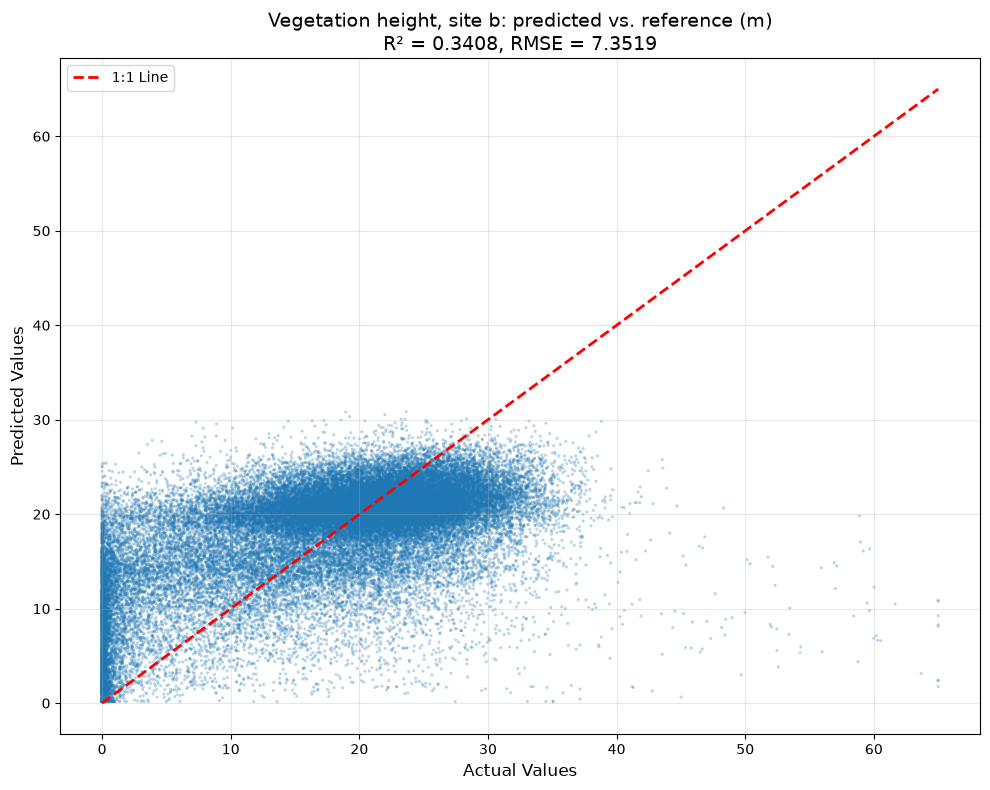

Fitted line: prediction = 0.36 × reference + 11.8 m


In [11]:
fig, scatter_metrics = geoai.plot_scatter(
    true_raster=files[(TEST_SITE, "vhm")],
    pred_raster=pred_path[TEST_SITE],
    sample_size=50000,
    fit_line=False,
    title=f"Vegetation height, site {TEST_SITE}: predicted vs. reference (m)",
)
valid = np.isfinite(pred[TEST_SITE])
x = ref[TEST_SITE][valid].astype("float64")
y = pred[TEST_SITE][valid].astype("float64")
slope = np.mean((x - x.mean()) * (y - y.mean())) / np.var(x)  # least-squares slope
intercept = y.mean() - slope * x.mean()
print(f"Fitted line: prediction = {slope:.2f} × reference + {intercept:.1f} m")

As on page 7, we fit the line ourselves in `float64`, because `geoai`'s `fit_line=True` is unreliable for millions of `float32` pixels. Here we use the least-squares formula directly (slope = covariance / variance), which gives the same result as `np.polyfit`. The cloud is far from the 1:1 line: almost all predictions lie between 5 and 28 m, whatever the reference height. The fitted slope of about 0.36 quantifies this compression: the model has learned that "forest is about 20 m high" and varies its predictions only cautiously around that value. The vertical stripe at 0 m consists of meadows, clearings and gaps, many of them predicted as 10–20 m tall. Reference values above about 45 m are rare and probably matching errors in the VHM rather than real trees; the model does not follow them, which is not a mistake.

,share,RMSE (m),MAE (m),bias (m)
height class,,,,
"0–2 m (meadow, clearing)",0.10,10.17,8.49,8.48
"2–10 m (shrubs, young trees)",0.11,10.02,8.83,8.46
10–20 m,0.32,5.30,4.35,2.79
20–30 m,0.42,5.61,4.29,-3.76
≥ 30 m (tall trees),0.05,14.35,12.44,-12.44


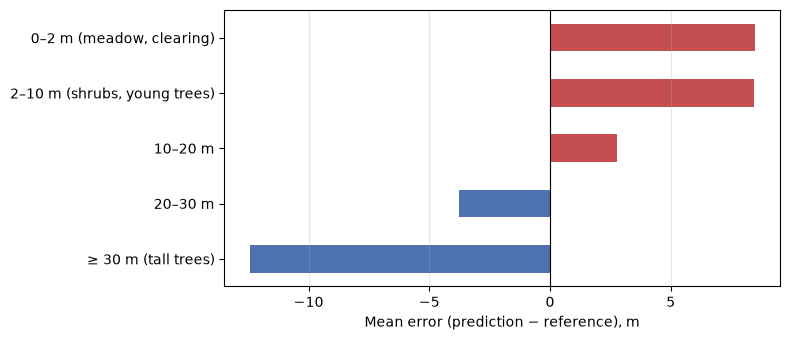

In [12]:
classes = [(0, 2, "0–2 m (meadow, clearing)"), (2, 10, "2–10 m (shrubs, young trees)"),
           (10, 20, "10–20 m"), (20, 30, "20–30 m"), (30, 65, "≥ 30 m (tall trees)")]
by_class = pd.DataFrame([
    {"height class": label,
     "share": np.mean((ref[TEST_SITE] >= lo) & (ref[TEST_SITE] < hi)),
     **regression_metrics(ref[TEST_SITE], pred[TEST_SITE], (ref[TEST_SITE] >= lo) & (ref[TEST_SITE] < hi))}
    for lo, hi, label in classes
]).set_index("height class")
display(by_class[["share", "RMSE (m)", "MAE (m)", "bias (m)"]].round(2))

fig, ax = plt.subplots(figsize=(8, 3.5))
by_class["bias (m)"].plot.barh(ax=ax, color=np.where(by_class["bias (m)"] > 0, "#c44e52", "#4c72b0"))
ax.axvline(0, color="black", lw=0.8)
ax.invert_yaxis()
ax.set_xlabel("Mean error (prediction − reference), m")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

The scene-wide {term}`bias <Bias>` of +0.4 m hides two large, opposite errors. Open land and low vegetation (below 10 m, a fifth of the site) are overestimated by about 8.5 m; trees above 30 m are underestimated by about 12 m. Only the classes between 10 and 30 m, close to the mean, are predicted reasonably well. This is the regression to the mean from page 7, much stronger here: when the input does not reveal the answer clearly, a model trained with {term}`mean squared error <Mean Squared Error>` (MSE) predicts values close to the average, because that minimises the squared error.

### J. Where are the errors?

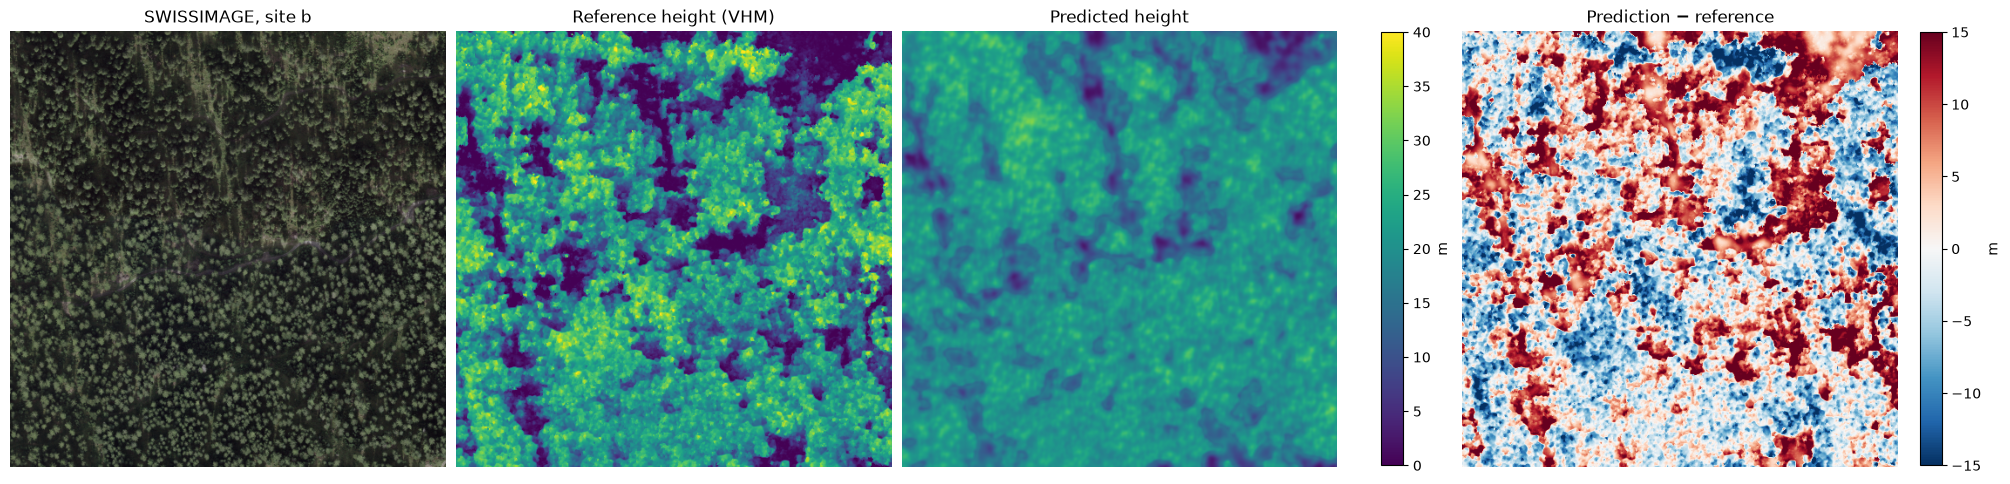

In [13]:
zoom = (slice(500, 1000), slice(500, 1000))  # a 500 x 500 m window
with rasterio.open(files[(TEST_SITE, "swissimage")]) as src:
    rgb = src.read()[(slice(None),) + zoom].transpose(1, 2, 0)

fig, axes = plt.subplots(1, 4, figsize=(20, 5.5), constrained_layout=True)
axes[0].imshow(rgb)
axes[0].set_title(f"SWISSIMAGE, site {TEST_SITE}")
for ax, arr, title in [(axes[1], ref[TEST_SITE], "Reference height (VHM)"), (axes[2], pred[TEST_SITE], "Predicted height")]:
    im = ax.imshow(arr[zoom], cmap="viridis", vmin=0, vmax=40)
    ax.set_title(title)
fig.colorbar(im, ax=axes[1:3], shrink=0.8, label="m")
im = axes[3].imshow((pred[TEST_SITE] - ref[TEST_SITE])[zoom], cmap="RdBu_r", vmin=-15, vmax=15)
axes[3].set_title("Prediction − reference")
fig.colorbar(im, ax=axes[3], shrink=0.8, label="m")
for ax in axes:
    ax.set_axis_off()
plt.show()

The zoom shows why. The reference map is detailed: individual crowns, gaps a few metres wide, sharp stand edges. The prediction is a smooth surface with values between about 10 and 25 m. It captures the larger structures (the more open area at the top, the denser stands in the south), but not the individual gaps and crowns. The residual map is therefore patchy: red where gaps and young stands are predicted too tall, blue where the tallest stands are predicted too low.

A continuous height map can still answer categorical questions. Thresholding both maps at 3 m, a common minimum height for forest, gives a forest/non-forest classification, which you can evaluate with the measures from L07:

In [14]:
ref_forest = ref[TEST_SITE] >= 3
pred_forest = pred[TEST_SITE] >= 3
valid = np.isfinite(pred[TEST_SITE])
agree = np.mean(ref_forest[valid] == pred_forest[valid])
iou = np.sum(ref_forest & pred_forest & valid) / np.sum((ref_forest | pred_forest) & valid)
print(f"Forest (≥ 3 m) vs. non-forest at site {TEST_SITE}: {agree:.1%} of pixels agree, IoU of forest {iou:.2f}")

Forest (≥ 3 m) vs. non-forest at site b: 90.3% of pixels agree, IoU of forest 0.90


For forest/non-forest, nine out of ten pixels agree and the IoU of forest is 0.90. That sounds far better than an R² of 0.34, but the two numbers answer different questions: at a 3 m threshold, a prediction of 15 m for a 25 m tree is "correct". Deriving classes from a continuous map is easy; the reverse is not, which is one reason to keep the continuous map.

### K. Effects of changing the settings

```{admonition} Our runs on an Apple M3 laptop
:class: tip
Errors on the test site, i.e. the site the model never saw. For comparison, predicting the training area's mean height everywhere gives an RMSE of 9.3 m on site B and 12.9 m on site A.

| Settings (training site A, test site B, unless noted) | Epochs | RMSE (m) | R² | Bias (m) |
| --- | --- | --- | --- | --- |
| `LOSS="mse"`, seed 0 (default) | 54 | 7.4 | 0.34 | +0.4 |
| `LOSS="mse"`, seed 1 | 51 | 7.5 | 0.32 | +0.1 |
| `LOSS="huber"`, seed 0 / seed 1 | 37 / 46 | 8.1 / 8.1 | 0.21 / 0.21 | +0.8 / +2.5 |
| `LOSS="l1"` | 44 | 8.1 | 0.19 | −2.8 |
| `LOSS="huber"`, `RESCALE_INPUT=False` | 65 | 7.7 | 0.28 | +1.1 |
| `LOSS="huber"`, `stride=64` (400 instead of 100 tiles) | 52 | 7.6 | 0.29 | −0.7 |
| `LOSS="mse"`, `LEARNING_RATE=1e-4` | 100 | 12.8 | −1.00 | −10.4 |
| `TRAIN_SITE="b"` (test site A), `LOSS="mse"` | 50 | 10.4 | 0.28 | −3.7 |
| Random forest on pixel colours (no context) | – | 9.6 | −0.12 | +1.9 |

- **Mean squared error (MSE) beat Huber loss and mean absolute error (MAE).** For heights in metres, `geoai`'s {term}`Huber loss <Huber Loss>` behaves almost like {term}`MAE <Mean Absolute Error>` (page 3), and both optimise something other than the squared error that RMSE measures. Two seeds gave nearly the same result, so the difference is real.
- **A learning rate of 1e-4 was too small.** After 100 epochs the predictions were still about 10 m too low everywhere, even though their correlation with the reference was already 0.57: the model had learned *where* trees are taller, but not *how tall*. The {term}`regression head <Regression Head>` starts near 0 and must reach values around 20 m, which takes many small steps. This is the situation from page 7, where a high correlation hides a large bias.
- **More overlapping tiles helped only a little**, at about three times the training time: more of the same site is not the same as more diverse data.
- **The wrongly scaled input did not perform clearly worse here.** The batch normalization after the first convolution partly rescales the features, and the network adapted during training. The scaling is still wrong, and the pretrained features are not used as intended; do not rely on the network to compensate.
- **Transfer depends on direction.** Trained on the lower forest of site B, the model underestimated the taller site A by 3.7 m on average: it rarely saw trees as tall as those in site A.
```

---

## 4. Python reactivation

Two NumPy patterns from this page are worth knowing:

- `src.read().reshape(3, -1).T` turns a `(bands, rows, columns)` image into a table with one row per pixel and one column per band, the format scikit-learn expects. `-1` lets NumPy compute the number of pixels. `.reshape(1500, 1500)` turns the predictions back into an image.
- `np.flatnonzero(mask)` returns the positions of all `True` values of a mask in that flattened order, and `rng.choice(..., 100_000, replace=False)` draws a random sample of them. Training the random forest on a sample keeps it fast; the underscore in `100_000` only makes the number easier to read.

---

## 5. Common pitfalls

- **Feeding 8-bit images to a model that expects 0–1 or reflectance × 10,000.** `geoai` does not warn; rescale yourself and check the value range of what goes into the model.
- **Reporting the training site's scores as accuracy.** The real test is a site, area or date the model has not seen, and the gap between the two is part of the result.
- **Skipping baselines.** An R² of 0.5 sounds modest, but may be a large improvement over the alternatives, or no improvement at all; only a baseline tells you which.
- **Ignoring value-dependent bias.** Most regression models underestimate the highest and overestimate the lowest values. If your question is about tall trees (or high biomass, or dense population), report errors for that group.
- **Forgetting that the reference has errors too.** The VHM comes from stereo matching, which is least reliable in deep shadows and steep terrain, exactly where the orthophoto is hardest to read as well.

---

## 6. Mini task

1. Set `TRAIN_SITE = "b"` and re-run the page. Is a model trained on site B better or worse at predicting site A than the other way round? Use the height histograms from step C to explain the difference.
2. Your project needs the area of forest taller than 25 m in a valley next to these sites. Based on steps I and J, would you use this model? What would you report alongside the estimate?

:::{dropdown} Sample solution
:class: note

1. In our run, the model trained on site B reached an RMSE of 10.4 m and R² 0.28 on site A, with a bias of −3.7 m; trained on site A, it reached 7.4 m and 0.34 on site B. The RMSE values are not directly comparable, because site A has more variable heights (standard deviation 12.3 m versus 9.1 m), but the bias tells the story: site B's training data contain few trees above 30 m, so the model rarely predicts such heights and underestimates the taller forest of site A. A model can only reproduce the range of values it has seen; training data should cover the range you want to predict.

2. Probably not on its own. Step I shows that the model underestimates tall trees systematically, so the area above 25 m would be underestimated as well, and by an amount that depends on the site. If you used it, report the held-out error *for tall trees* (not the scene-wide RMSE), the bias in that class, and the area estimate with that uncertainty. Better: check whether LiDAR or the national VHM itself covers the valley, since the model is only useful where no 3D data exist.
:::

---

## 7. Key takeaways

- The workflow of pages 4–7 transfers unchanged to a real measurement target: inspect, scale, tile, split by location, train, predict, evaluate.
- Check the input scaling: 8-bit images must be scaled to 0–1 before `geoai` sees them.
- Evaluate on a different site and against baselines; the comparison with a per-pixel model shows how much the spatial context contributes.
- Regression models compress the range: low vegetation is overestimated and tall trees are underestimated, so report errors per value class when the extremes matter.
- A continuous map can still be thresholded into classes (forest/non-forest), but not the other way round.

### Further reading

- Ginzler and Hobi (2015), ["Countrywide stereo-image matching for updating digital surface models in the framework of the Swiss National Forest Inventory"](https://doi.org/10.3390/rs70404343), *Remote Sensing* 7, 4343–4370 — how the vegetation height model used as the reference on this page is produced.
- Tolan et al. (2024), ["Very high resolution canopy height maps from RGB imagery using self-supervised vision transformer and convolutional decoder trained on aerial lidar"](https://doi.org/10.1016/j.rse.2023.113888), *Remote Sensing of Environment* 300, 113888 — the same task at global scale, including a discussion of underestimated tall trees.
- swisstopo, [SWISSIMAGE 10 cm](https://www.swisstopo.admin.ch/en/orthoimage-swissimage-10) — the orthophoto product, free to use with attribution.

*Data: SWISSIMAGE © swisstopo; vegetation height model © Swiss National Forest Inventory (NFI), WSL/FOEN.*